In [2]:
from sys import path
path.append("../src")

import time

from validation import check_sigma_daily_scale
from metrics import summarize_daily, summarize_minute, summarize_intraday_drawdown
from analysis import decompose_fills, select_days, compare_strategies
from simulation import run_simulation
from strategies import NaiveStrategy, ASLiteralStrategy, HardLimitStrategy, HybridStrategy
from config import FEATURES_PATH
check_sigma_daily_scale(FEATURES_PATH)



import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path




OUT = Path("../results/plots")
OUT.mkdir(parents=True, exist_ok=True)

Pipeline-Dimensionstest sigma_ewma_usd (../data/processed/nvda_202606_features.parquet):
  mean(sigma_ewma_usd) = 4.465511
  mean(mid)            = 206.761738
  implizite Tagesvol.  = 2.1597%
  plausibler Bereich   = [0.50%, 10.00%]
  Ergebnis: BESTANDEN


In [3]:
from config import (FEATURES_PATH, K_MAIN, GAMMA_SWEEP, NAIVE_HALF_SPREAD,
                    Q_MAX, TICK_SIZE, K_MIN, K_MAX, ORDER_SIZE,
                    FILL_RULE, ladder_column_name)

keep = (["ts_recv", "trading_day", "mid", "spread", "imbalance_l1",
         "sigma_ewma_usd", "time_to_close",
         "sell_trade_price_min", "buy_trade_price_max",
         "sell_trade_volume", "buy_trade_volume"]
        + [f"{s}_{t}_{i:02d}" for s in ("bid", "ask") for t in ("px", "sz") for i in range(10)]
        + [ladder_column_name(l, j) for l in ("sell", "buy") for j in range(K_MIN, K_MAX + 1)])

feat = pd.read_parquet(FEATURES_PATH, columns=keep)
print(f"{len(feat):,} Bins, {feat['trading_day'].nunique()} Handelstage, "
      f"{feat['trading_day'].min()} bis {feat['trading_day'].max()}")
print(f"k={K_MAIN}  hs={NAIVE_HALF_SPREAD}  q_max={Q_MAX}  size={ORDER_SIZE}  rule={FILL_RULE}")

980,554 Bins, 21 Handelstage, 20260601 bis 20260630
k=21.4454  hs=0.05  q_max=300.0  size=20.0  rule=conservative


In [4]:
strategies = {
    "naive":      NaiveStrategy(half_spread=NAIVE_HALF_SPREAD, tick_size=TICK_SIZE),
    "hard_limit": HardLimitStrategy(half_spread=NAIVE_HALF_SPREAD, q_max=Q_MAX, tick_size=TICK_SIZE),
}
for i, g in enumerate(GAMMA_SWEEP, 1):
    strategies[f"as_g{i}"]     = ASLiteralStrategy(gamma=g, k=K_MAIN, tick_size=TICK_SIZE)
    strategies[f"hybrid_g{i}"] = HybridStrategy(gamma=g, k=K_MAIN, q_max=Q_MAX, tick_size=TICK_SIZE)

for i, g in enumerate(GAMMA_SWEEP, 1):
    print(f"g{i} = {g:.4e}")

g1 = 1.0000e-05
g2 = 3.0000e-05
g3 = 1.0000e-04


In [5]:
one = select_days(feat, n_days=1)
for name, s in strategies.items():
    rbd, ds = run_simulation(one, s)
    r = pd.concat(rbd.values(), ignore_index=True)
    print(f"{name:12s} fills={int(r['n_fills'].sum()):6,}  "
          f"vol={r['fill_size'].sum():8,.0f}  pnl={ds['final_pnl'].sum():10,.2f}")

naive        fills= 1,860  vol=  27,742  pnl=   -350.90
hard_limit   fills= 1,802  vol=  26,838  pnl=   -220.92
as_g1        fills= 3,034  vol=  40,826  pnl=   -759.03
hybrid_g1    fills= 3,034  vol=  40,826  pnl=   -759.03
as_g2        fills= 3,572  vol=  45,598  pnl= -1,000.67
hybrid_g2    fills= 3,572  vol=  45,598  pnl= -1,000.67
as_g3        fills= 4,442  vol=  54,337  pnl= -1,312.92
hybrid_g3    fills= 4,442  vol=  54,337  pnl= -1,312.92


In [6]:
runs = {}
for name, s in strategies.items():
    t0 = time.time()
    runs[name] = run_simulation(feat, s)
    print(f"{name:12s} fertig in {time.time()-t0:.0f}s", flush=True)

naive        fertig in 33s
hard_limit   fertig in 33s
as_g1        fertig in 32s
hybrid_g1    fertig in 33s
as_g2        fertig in 33s
hybrid_g2    fertig in 34s
as_g3        fertig in 33s
hybrid_g3    fertig in 34s


In [7]:
table = compare_strategies(runs)
table.round(4)

,strategy,n_fills,volume,quoted_ct,impact_ct,realized_ct,realized_total,inventory_total,final_pnl,avg_abs_inv,inv_q99,max_abs_inv,final_inv,sharpe_d,sortino_d,var_95_d,es_95_d,max_dd_d
0,naive,20367,282375.0,5.2180,-7.0536,-1.8356,-5183.325,-20013.735,-25197.06,601.7727,2039.0,2356.0,0.0,-5.1968,-5.2629,-8299.13,-10194.695,-31696.14
1,hard_limit,19091,263991.0,5.2180,-7.0798,-1.8618,-4914.965,-1978.325,-6893.29,182.7385,315.0,319.0,0.0,-5.7264,-7.3829,-2003.91,-2038.405,-8239.37
2,as_g1,22613,307417.0,4.6859,-6.6093,-1.9234,-5912.780,-678.680,-6591.46,51.3004,258.3,786.0,0.0,-13.7093,-15.3086,-778.28,-1049.615,-6591.46
3,hybrid_g1,22508,305690.0,4.6829,-6.6160,-1.9332,-5909.475,-84.815,-5994.29,50.4430,252.0,319.0,0.0,-13.7986,-17.2809,-759.03,-885.375,-5994.29
4,as_g2,24512,326377.0,4.2455,-6.2304,-1.9849,-6478.285,-766.775,-7245.06,30.2276,164.0,716.0,0.0,-16.7464,-17.2782,-1000.67,-1100.945,-7245.06
5,hybrid_g2,24456,325390.0,4.2423,-6.2337,-1.9915,-6480.010,-503.370,-6983.38,30.0369,162.0,319.0,0.0,-17.1367,-17.7536,-1000.67,-1027.790,-6983.38
6,as_g3,30528,387083.0,3.3382,-5.3747,-2.0365,-7882.950,-981.410,-8864.36,16.3225,121.0,598.0,0.0,-20.5844,-20.5844,-1110.86,-1211.890,-8864.36
7,hybrid_g3,30493,386492.0,3.3353,-5.3762,-2.0409,-7888.065,-961.895,-8849.96,16.2672,121.0,318.0,0.0,-20.6284,-20.6284,-1110.86,-1211.890,-8849.96


In [8]:
rows = []
for name, (rbd, ds) in runs.items():
    r = pd.concat(rbd.values(), ignore_index=True)
    q = r.loc[~r["is_liquidation"]]
    rows.append({
        "strategy": name,
        "one_sided":   (q["bid_active"] ^ q["ask_active"]).mean(),
        "binding":     (q["inventory"].abs() >= Q_MAX).mean(),
        "clamped":     (r["bid_clamped"] | r["ask_clamped"]).mean(),
        "mean_abs_q":   q["inventory"].abs().mean(),
        "max_abs_q":    q["inventory"].abs().max(),
        "mean_skew_ct": (q["decision_mid"] - q["reference_price"]).abs().mean() * 100,
        "fill_rate":    r["n_fills"].sum() / (r["bid_active"].sum() + r["ask_active"].sum()),
    })
pd.DataFrame(rows).round(4)

,strategy,one_sided,binding,clamped,mean_abs_q,max_abs_q,mean_skew_ct,fill_rate
0,naive,0.0000,0.5909,0.0000,601.7856,2356.0,0.0000,0.0104
1,hard_limit,0.0964,0.0964,0.0000,182.7425,319.0,0.0000,0.0102
2,as_g1,0.0000,0.0065,0.0014,51.3015,786.0,0.3864,0.0116
3,hybrid_g1,0.0037,0.0037,0.0014,50.4441,319.0,0.3861,0.0115
4,as_g2,0.0000,0.0023,0.0035,30.2283,716.0,0.6436,0.0125
5,hybrid_g2,0.0016,0.0016,0.0035,30.0376,319.0,0.6435,0.0125
6,as_g3,0.0000,0.0004,0.0093,16.3229,598.0,1.1911,0.0156
7,hybrid_g3,0.0004,0.0004,0.0093,16.2675,318.0,1.1911,0.0156


In [9]:
rows = []
for name, (rbd, ds) in runs.items():
    m  = summarize_minute(rbd, alpha=0.99)
    dd = summarize_intraday_drawdown(rbd)
    rows.append({
        "strategy": name,
        "minute_var_99": m["minute_var"],
        "minute_es_99":  m["minute_es"],
        "minute_vol":    m["minute_pnl_vol"],
        "worst_intraday_dd": dd["worst_intraday_drawdown"],
        "tail_top_day_share": max(m["tail_obs_by_day"].values()) / m["n_tail_obs"],
    })
pd.DataFrame(rows).round(4)

,strategy,minute_var_99,minute_es_99,minute_vol,worst_intraday_dd,tail_top_day_share
0,naive,-535.0027,-737.0975,157.3811,-14652.855,0.3902
1,hard_limit,-147.2065,-194.0821,45.4664,-2614.300,0.1463
2,as_g1,-51.0593,-96.0551,17.7270,-1331.125,0.2317
3,hybrid_g1,-49.9438,-82.7444,15.7777,-1022.845,0.2317
4,as_g2,-34.3063,-65.4545,11.3836,-1211.395,0.1829
5,hybrid_g2,-33.7209,-61.7542,10.7752,-1174.410,0.1829
6,as_g3,-22.6038,-45.0010,7.3920,-1357.520,0.1220
7,hybrid_g3,-22.6038,-44.7249,7.3675,-1357.520,0.1220


In [10]:
rows = []
for name, (rbd, ds) in runs.items():
    r = pd.concat(rbd.values(), ignore_index=True)
    p = decompose_fills(r, float(ds["final_pnl"].sum()))
    slip = float((ds["final_pnl"] - ds["pnl_before_liquidation"]).sum())
    rows.append({
        "strategy": name,
        "quoted":      p["quoted_total"],
        "impact":      p["impact_total"],
        "inventory":   p["inventory_total"] - slip,
        "liquidation": slip,
        "total":       p["final_pnl"],
        "quoted_ct":   p["quoted_per_share"] * 100,
        "impact_ct":   p["impact_per_share"] * 100,
    })
dec = pd.DataFrame(rows)
dec["check"] = dec[["quoted","impact","inventory","liquidation"]].sum(axis=1) - dec["total"]
dec.round(4)

,strategy,quoted,impact,inventory,liquidation,total,quoted_ct,impact_ct,check
0,naive,14734.410,-19917.735,-19668.070,-345.665,-25197.06,5.2180,-7.0536,0.0
1,hard_limit,13775.015,-18689.980,-1920.995,-57.330,-6893.29,5.2180,-7.0798,0.0
2,as_g1,14405.315,-20318.095,-620.050,-58.630,-6591.46,4.6859,-6.6093,0.0
3,hybrid_g1,14315.015,-20224.490,-51.350,-33.465,-5994.29,4.6829,-6.6160,-0.0
4,as_g2,13856.220,-20334.505,-716.600,-50.175,-7245.06,4.2455,-6.2304,0.0
5,hybrid_g2,13803.895,-20283.905,-470.430,-32.940,-6983.38,4.2423,-6.2337,-0.0
6,as_g3,12921.770,-20804.720,-939.730,-41.680,-8864.36,3.3382,-5.3747,0.0
7,hybrid_g3,12890.660,-20778.725,-931.750,-30.145,-8849.96,3.3353,-5.3762,0.0


In [11]:
rows = []
for name, (rbd, ds) in runs.items():
    r = pd.concat(rbd.values(), ignore_index=True)
    q = r.loc[~r["is_liquidation"]]
    d = summarize_daily(ds); m = summarize_minute(rbd, alpha=0.99)
    p = decompose_fills(r, float(ds["final_pnl"].sum()))
    rows.append({
        "Strategy":      name,
        "P&L / day":     d["mean_daily_pnl"],
        "sd(P&L)":       d["std_daily_pnl"],
        "mean |q|":      q["inventory"].abs().mean(),
        "sd(final q)":   ds["inventory_before_liquidation"].std(),
        "VaR 99 (min)":  m["minute_var"],
        "Realised ct":   p["realized_per_share"] * 100,
    })
main = pd.DataFrame(rows).set_index("Strategy")
main.round(2)

,P&L / day,sd(P&L),mean |q|,sd(final q),VaR 99 (min),Realised ct
Strategy,,,,,,
naive,-1199.86,3665.18,601.79,1016.63,-535.00,-1.84
hard_limit,-328.25,909.97,182.74,196.18,-147.21,-1.86
as_g1,-313.88,363.45,51.30,308.36,-51.06,-1.92
hybrid_g1,-285.44,328.39,50.44,154.34,-49.94,-1.93
as_g2,-345.00,327.04,30.23,258.10,-34.31,-1.98
hybrid_g2,-332.54,308.05,30.04,155.32,-33.72,-1.99
as_g3,-422.11,325.53,16.32,215.47,-22.60,-2.04
hybrid_g3,-421.43,324.31,16.27,155.70,-22.60,-2.04


In [12]:
dec_ct = dec.set_index("strategy")[["quoted_ct", "impact_ct"]].copy()
dec_ct["realised_ct"] = dec_ct["quoted_ct"] + dec_ct["impact_ct"]
dec_ct["inventory $"] = dec.set_index("strategy")["inventory"]
dec_ct["total $"]     = dec.set_index("strategy")["total"]
dec_ct.round(2)

,quoted_ct,impact_ct,realised_ct,inventory $,total $
strategy,,,,,
naive,5.22,-7.05,-1.84,-19668.07,-25197.06
hard_limit,5.22,-7.08,-1.86,-1920.99,-6893.29
as_g1,4.69,-6.61,-1.92,-620.05,-6591.46
hybrid_g1,4.68,-6.62,-1.93,-51.35,-5994.29
as_g2,4.25,-6.23,-1.98,-716.60,-7245.06
hybrid_g2,4.24,-6.23,-1.99,-470.43,-6983.38
as_g3,3.34,-5.37,-2.04,-939.73,-8864.36
hybrid_g3,3.34,-5.38,-2.04,-931.75,-8849.96


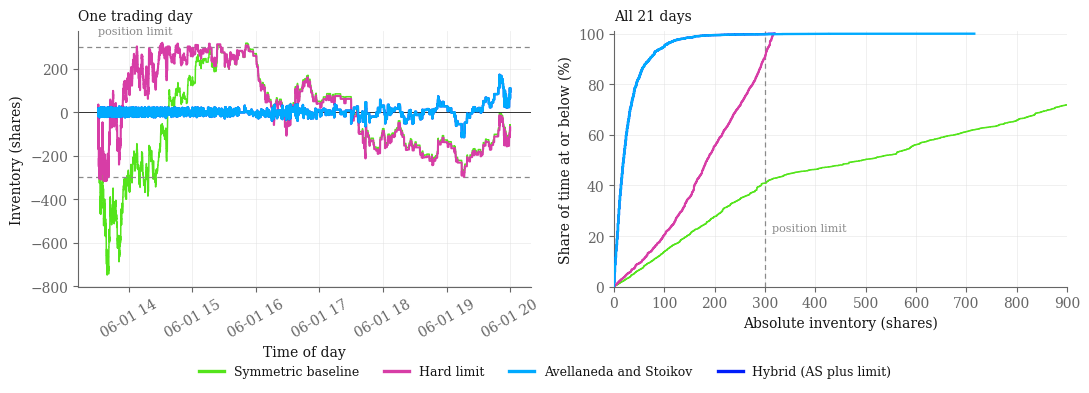

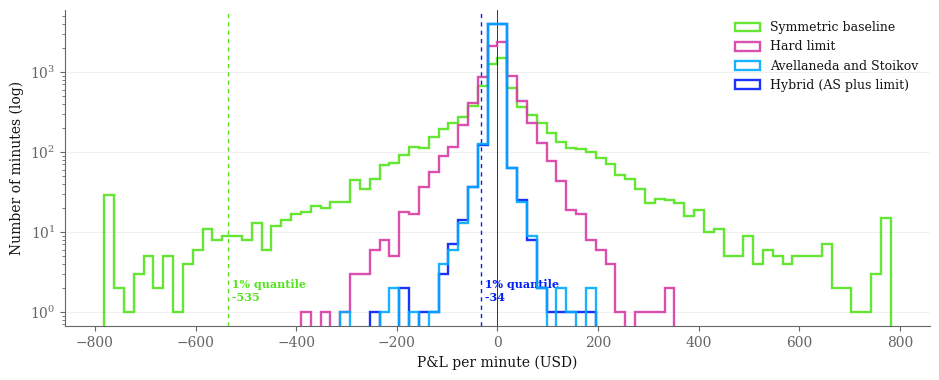

Geschrieben: ../results/plots/inventory_overview.pdf
Geschrieben: ../results/plots/pnl_minute_tail.pdf


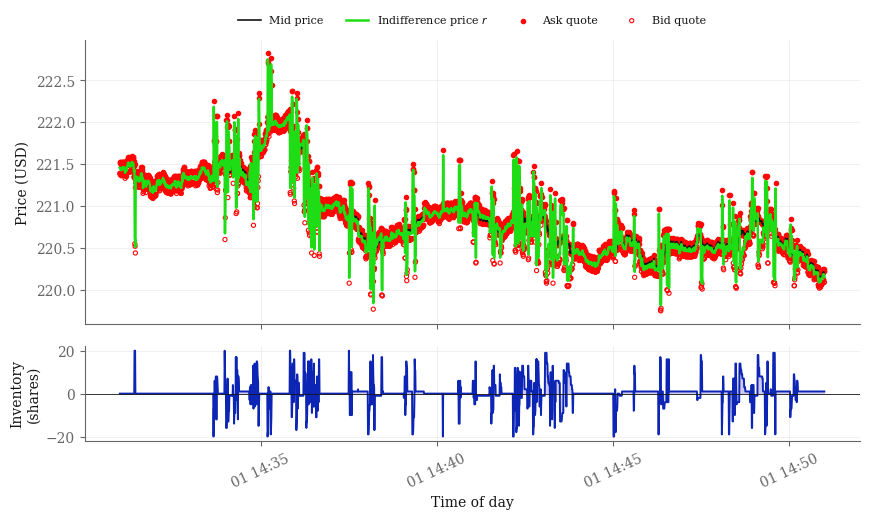

../results/plots/as_quotes.pdf


In [13]:
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#666666",
    "axes.labelcolor": "#141414",
    "text.color": "#141414",
    "xtick.color": "#666666",
    "ytick.color": "#666666",
    "grid.color": "#DDDDDD",
    "grid.linewidth": 0.6,
    "legend.frameon": False,
    "figure.facecolor": "white",
})

SHOW = ["naive", "hard_limit", "as_g2", "hybrid_g2"]

STYLE = {
    "naive":      dict(label="Symmetric baseline",     color="#54E41B", lw=1.1, zorder=2),
    "hard_limit": dict(label="Hard limit",             color="#D73DA6", lw=1.5, zorder=3),
    "as_g2":      dict(label="Avellaneda and Stoikov", color="#00AAFF", lw=1.7, zorder=5),
    "hybrid_g2":  dict(label="Hybrid (AS plus limit)", color="#001DFA", lw=1.7, zorder=4),
}
GREY = "#8A8A8A"
LIMIT = 300


def _steps(name):
    r = pd.concat(runs[name][0].values(), ignore_index=True)
    return r.loc[~r["is_liquidation"]]



fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))

day = sorted(runs["naive"][0])[0]
for n in SHOW:
    d = runs[n][0][day]
    d = d.loc[~d["is_liquidation"]]
    ax1.plot(d["timestamp"], d["inventory"], **STYLE[n])

ax1.axhline(0, color="#141414", lw=.6)
for s in (LIMIT, -LIMIT):
    ax1.axhline(s, color=GREY, ls=(0, (4, 3)), lw=.9)
ax1.text(d["timestamp"].iloc[3], LIMIT + 60, "position limit",
         fontsize=8, color=GREY)
ax1.set_ylabel("Inventory (shares)")
ax1.set_xlabel("Time of day")
ax1.set_title("One trading day", fontsize=10, loc="left", pad=8)
ax1.grid(alpha=.5)
ax1.tick_params(axis="x", rotation=30)

for n in SHOW:
    v = np.sort(_steps(n)["inventory"].abs().values)
    ax2.plot(v, np.arange(1, len(v) + 1) / len(v) * 100, **STYLE[n])

ax2.axvline(LIMIT, color=GREY, ls=(0, (4, 3)), lw=.9)
ax2.text(LIMIT + 15, 22, "position limit", fontsize=8, color=GREY)
ax2.set_xlim(0, 900)
ax2.set_ylim(0, 101)
ax2.set_xlabel("Absolute inventory (shares)")
ax2.set_ylabel("Share of time at or below (%)")
ax2.set_title("All 21 days", fontsize=10, loc="left", pad=8)
ax2.grid(alpha=.5)

handles = [plt.Line2D([], [], color=STYLE[n]["color"], lw=2.4,
                      label=STYLE[n]["label"]) for n in SHOW]
fig.legend(handles=handles, ncol=4, loc="lower center",
           bbox_to_anchor=(0.5, -0.04), fontsize=9)

plt.tight_layout()
plt.savefig(OUT / "inventory_overview.pdf", bbox_inches="tight")
plt.show()


per_min = {}
for n in SHOW:
    parts = []
    for day_result in runs[n][0].values():
        s = (day_result.set_index("timestamp")["pnl"]
             .sort_index().resample("1min").last().dropna())
        parts.append(s.diff().dropna())
    per_min[n] = pd.concat(parts).values

lim = np.percentile(np.abs(per_min["naive"]), 99.5)
bins = np.linspace(-lim, lim, 81)

fig, ax = plt.subplots(figsize=(9.5, 3.9))
for n in SHOW:
    ax.hist(np.clip(per_min[n], -lim, lim), bins=bins, histtype="step",
            color=STYLE[n]["color"], lw=1.7, alpha=.9,
            zorder=STYLE[n]["zorder"], label=STYLE[n]["label"])

ax.set_yscale("log")
ax.axvline(0, color="#141414", lw=.6)
ax.set_xlabel("P&L per minute (USD)")
ax.set_ylabel("Number of minutes (log)")
ax.legend(fontsize=9, loc="upper right")
ax.grid(alpha=.5, axis="y")

for n in ("naive", "hybrid_g2"):
    q = np.percentile(per_min[n], 1)
    ax.axvline(q, color=STYLE[n]["color"], ls=(0, (3, 3)), lw=1.0)
    ax.text(q, 1.3, f" 1% quantile\n {q:,.0f}", fontsize=8, fontweight="bold",
            color=STYLE[n]["color"], ha="left", va="bottom")

plt.tight_layout()
plt.savefig(OUT / "pnl_minute_tail.pdf", bbox_inches="tight")
plt.show()

print("Geschrieben:", OUT / "inventory_overview.pdf")
print("Geschrieben:", OUT / "pnl_minute_tail.pdf")



STRAT = "as_g3"          
WINDOW_MINUTES = 20      

day = sorted(runs[STRAT][0])[0]
d = runs[STRAT][0][day]
d = d.loc[~d["is_liquidation"]].copy()

start = d["timestamp"].iloc[0] + pd.Timedelta(minutes=60)
win = d.loc[(d["timestamp"] >= start) &
            (d["timestamp"] < start + pd.Timedelta(minutes=WINDOW_MINUTES))]

fig, (axp, axq) = plt.subplots(
    2, 1, figsize=(10, 5.2), sharex=True,
    gridspec_kw={"height_ratios": [3, 1], "hspace": 0.12})

axp.plot(win["timestamp"], win["decision_mid"], color="#141414", lw=1.2,
         label="Mid price", zorder=3)
axp.plot(win["timestamp"], win["reference_price"], color="#1EDD14", lw=1.8,
         label="Indifference price $r$", zorder=4)
axp.scatter(win["timestamp"], win["ask_quote"], s=9, color="#FF0505",
            label="Ask quote", zorder=2)
axp.scatter(win["timestamp"], win["bid_quote"], s=9, facecolors="none",
            edgecolors="#FF0505", linewidths=.8, label="Bid quote", zorder=2)

axp.set_ylabel("Price (USD)")
axp.legend(fontsize=8, ncol=4, loc="lower center",
           bbox_to_anchor=(0.5, 1.01))
axp.grid(alpha=.5)

axq.fill_between(win["timestamp"], win["inventory"], 0,
                 color="#260DB2", alpha=.22, linewidth=0)
axq.plot(win["timestamp"], win["inventory"], color="#0C25B4", lw=1.4)
axq.axhline(0, color="#141414", lw=.6)
axq.set_ylabel("Inventory\n(shares)")
axq.set_xlabel("Time of day")
axq.grid(alpha=.5)
axq.tick_params(axis="x", rotation=25)

plt.savefig(OUT / "as_quotes.pdf", bbox_inches="tight")
plt.show()

print(OUT / "as_quotes.pdf")